# Final comparison: CNN, SVM, and Random Forest

This notebook combines saved test-set artifacts for the three deployable models. All metrics and plots are calculated from the result files; no model is retrained here.

## Load saved evaluation data

Read the CNN evaluation row and classical verification export. Keep the three model names and metric columns consistent for the charts that follow.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
if not (ROOT / "outputs").is_dir():
    ROOT = ROOT.parent
FIGURES = ROOT / "outputs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

## Combine metrics from files

Read accuracy, macro precision, macro recall, and macro-F1 directly from the saved CNN and classical CSVs. The classical CSV is generated by `scripts/verify_classical.py`.

In [2]:
metric_columns = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
cnn = pd.read_csv(ROOT / "outputs" / "cnn" / "eval" / "model_comparison_row.csv").iloc[0]
classical = pd.read_csv(ROOT / "outputs" / "classical" / "model_comparison.csv")
model_rows = [{"Model": "CNN", **{k: float(cnn[k]) for k in metric_columns}}]
display_names = {"SVM_tuned": "SVM", "RF_tuned": "Random Forest"}
for row in classical[classical["model"].isin(display_names)].to_dict("records"):
    model_rows.append({"Model": display_names[row["model"]], **{k: float(row[k]) for k in metric_columns}})
comparison = pd.DataFrame(model_rows).set_index("Model")
display(comparison.rename(columns={"accuracy": "Accuracy", "precision_macro": "Precision (macro)",
                                   "recall_macro": "Recall (macro)", "f1_macro": "Macro-F1"}).round(3))

,Accuracy,Precision (macro),Recall (macro),Macro-F1
Model,,,,
CNN,0.557,0.555,0.566,0.544
SVM,0.553,0.594,0.556,0.554
Random Forest,0.477,0.498,0.491,0.473


## Overall metric comparison

Plot grouped bars for accuracy, macro precision, macro recall, and macro-F1. Save the figure to `outputs/figures/` for the report and site assets.

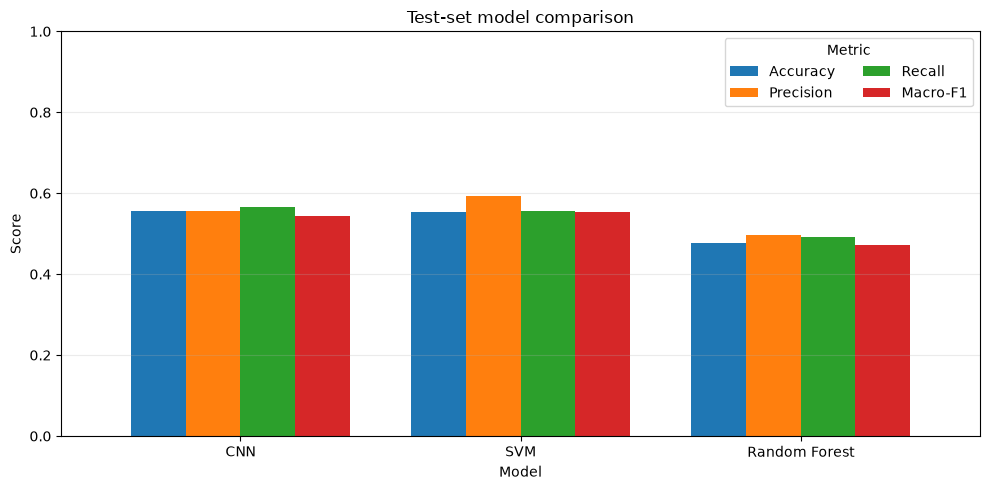

The highest accuracy in these files is **CNN** (0.557); the observed accuracy range is 0.080. Differences around **?3 percentage points** are within expected noise for this test set of 300 clips from 5 actors.

In [3]:
metric_labels = {"accuracy": "Accuracy", "precision_macro": "Precision",
                 "recall_macro": "Recall", "f1_macro": "Macro-F1"}
fig, ax = plt.subplots(figsize=(10, 5))
comparison.rename(columns=metric_labels).plot(kind="bar", ax=ax, width=0.78)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Test-set model comparison")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Metric", ncol=2)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
metric_fig = FIGURES / "model_metric_comparison.png"
fig.savefig(metric_fig, dpi=160, bbox_inches="tight")
display(fig)
best_model = comparison["accuracy"].idxmax()
best_accuracy = comparison["accuracy"].max()
accuracy_range = comparison["accuracy"].max() - comparison["accuracy"].min()
display(Markdown(f"The highest accuracy in these files is **{best_model}** ({best_accuracy:.3f}); the observed accuracy range is {accuracy_range:.3f}. Differences around **?3 percentage points** are within expected noise for this test set of 300 clips from 5 actors."))
plt.close(fig)

## Per-emotion F1 comparison

Read each model's per-class classification report and plot the F1-score for all emotion labels. The note below the figure reports the strongest class/model pair derived from those report files, plus the test-set uncertainty caveat.

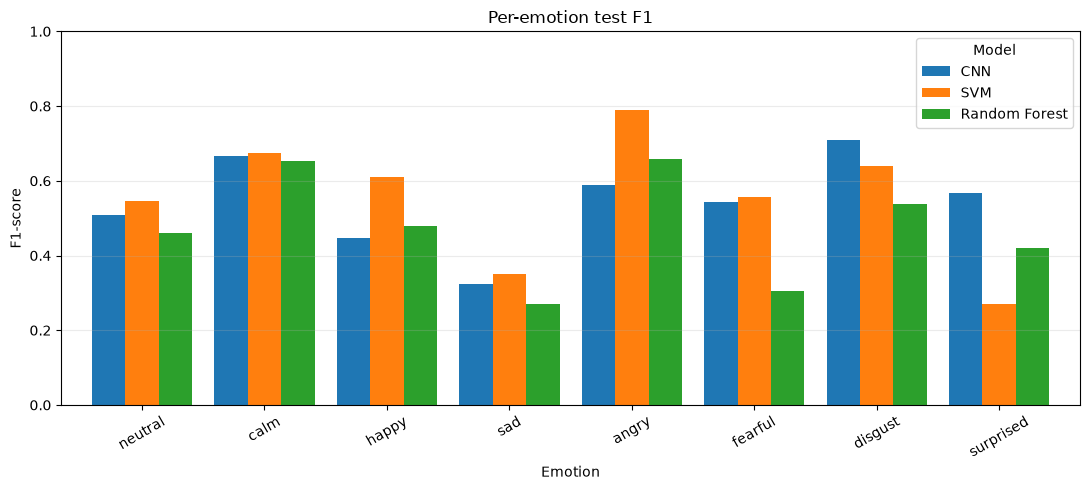

The strongest model/class pair in the displayed reports is **SVM** on **angry** (F1=0.789). Differences around **?3 percentage points** are within expected noise for 300 test clips from 5 actors.

In [4]:
emotion_order = ["neutral", "calm", "happy", "sad", "angry", "fearful", "disgust", "surprised"]
report_paths = {
    "CNN": ROOT / "outputs" / "cnn" / "eval" / "classification_report_CNN.csv",
    "SVM": ROOT / "outputs" / "classical" / "classification_report_SVM_tuned.csv",
    "Random Forest": ROOT / "outputs" / "classical" / "classification_report_RF_tuned.csv"
}
f1_tables = {}
for model, path in report_paths.items():
    report = pd.read_csv(path, index_col=0)
    f1_tables[model] = report.loc[emotion_order, "f1-score"]
f1_frame = pd.DataFrame(f1_tables)
ax = f1_frame.plot(kind="bar", figsize=(11, 5), width=0.82)
ax.set_ylim(0, 1)
ax.set_ylabel("F1-score")
ax.set_title("Per-emotion test F1")
ax.set_xlabel("Emotion")
ax.tick_params(axis="x", rotation=30)
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Model")
fig = ax.get_figure()
fig.tight_layout()
f1_fig = FIGURES / "per_emotion_f1.png"
fig.savefig(f1_fig, dpi=160, bbox_inches="tight")
display(fig)
best_emotion, best_model = f1_frame.stack().idxmax()
best_f1 = f1_frame.stack().max()
display(Markdown(f"The strongest model/class pair in the displayed reports is **{best_model}** on **{best_emotion}** (F1={best_f1:.3f}). Differences around **?3 percentage points** are within expected noise for 300 test clips from 5 actors."))
plt.close(fig)

## Confusion matrices side by side

Load the three saved 8-by-8 confusion-matrix CSVs and display them using a common color scale. The note identifies the largest off-diagonal confusion calculated from these matrices.

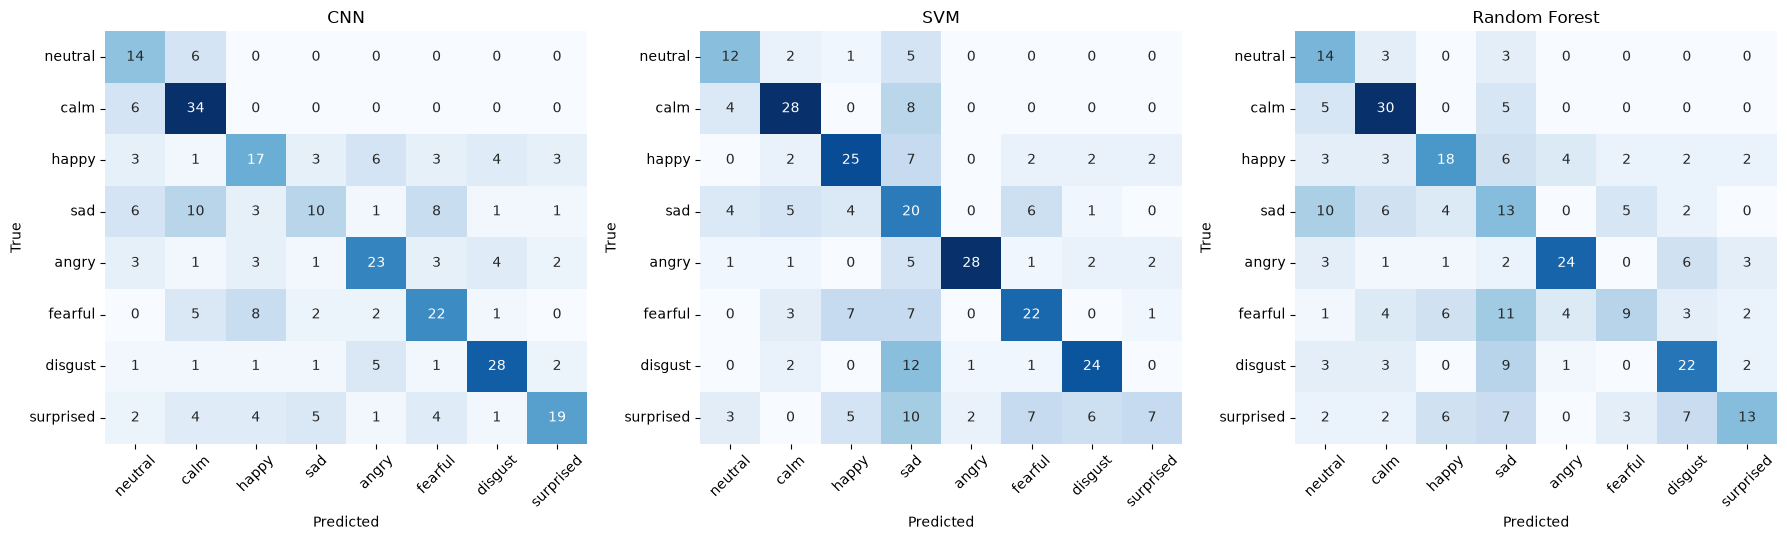

The largest off-diagonal count is **12** for **SVM**: true **disgust** predicted as **sad**. Each matrix covers 300 test clips from 5 actors; differences around **?3 percentage points** are within expected noise.

In [5]:
confusion_paths = {
    "CNN": ROOT / "outputs" / "cnn" / "eval" / "confusion_matrix_CNN.csv",
    "SVM": ROOT / "outputs" / "classical" / "confusion_matrix_SVM_tuned.csv",
    "Random Forest": ROOT / "outputs" / "classical" / "confusion_matrix_RF_tuned.csv"
}
matrices = {name: pd.read_csv(path, index_col=0).loc[emotion_order, emotion_order]
            for name, path in confusion_paths.items()}
fig, axes = plt.subplots(1, len(matrices), figsize=(18, 5.5))
for ax, (name, matrix) in zip(axes, matrices.items()):
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=emotion_order, yticklabels=emotion_order)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
confusion_fig = FIGURES / "confusion_matrices.png"
fig.savefig(confusion_fig, dpi=160, bbox_inches="tight")
display(fig)
off_diagonal = []
for model, matrix in matrices.items():
    for true_emotion in emotion_order:
        for predicted_emotion in emotion_order:
            if true_emotion != predicted_emotion:
                off_diagonal.append((int(matrix.loc[true_emotion, predicted_emotion]), model,
                                     true_emotion, predicted_emotion))
count, model, true_emotion, predicted_emotion = max(off_diagonal)
test_clips = int(next(iter(matrices.values())).to_numpy().sum())
labels = pd.read_csv(ROOT / "data" / "labels.csv")
test_actors = labels.loc[labels["split"] == "test", "actor"].nunique()
display(Markdown(f"The largest off-diagonal count is **{count}** for **{model}**: true **{true_emotion}** predicted as **{predicted_emotion}**. Each matrix covers {test_clips} test clips from {test_actors} actors; differences around **?3 percentage points** are within expected noise."))
plt.close(fig)